# Patient-specific baseline: seven movement features
Run the two code cells in order. The first processes the baseline and establishes mean ±3 sample SD. The second processes both test recordings and plots seven feature panels per file, plus segmentation checks.

Features: start-to-end orientation error; peak orientation excursion; mean, peak, and SD of angular speed; acceleration-magnitude SD; high-to-low frequency-power ratio. Duration, movement-axis deviation, and off-axis rotational energy fraction are excluded. The separate gravity-alignment experiment is not included.

All detected baseline reps are used provisionally. Set `APPROVED_BASELINE_REPS` after reviewing the baseline segmentation and movement quality. Thresholds are fixed before testing. Red points indicate departures from this small baseline, not proven exercise errors. Removing directional features means a different-axis movement with similar range and speed may go undetected.

Orientation features describe estimated watch motion, not anatomical joint angles. Invalid samples are removed and short gaps interpolated; larger gaps stop processing. 50 Hz recordings are anti-alias filtered to 25 Hz. The spectral ratio is exploratory, not a tremor diagnosis, and original sampling differences cannot be undone. Inspect rep boundaries, particularly any unconfirmed final movement. Duration is still used internally for segmentation checks. This notebook does not modify input recordings.


  Sensor 1: excluding 0 invalid samples.
  Sensor 2: excluding 0 invalid samples.
  Timestamp estimate: 25.00 Hz; using a 25 Hz uniform grid.
  Stillness check failed: no gyro bias correction applied.
  Source: ~25.0 Hz; analysis: 25 Hz; 9 candidate reps.


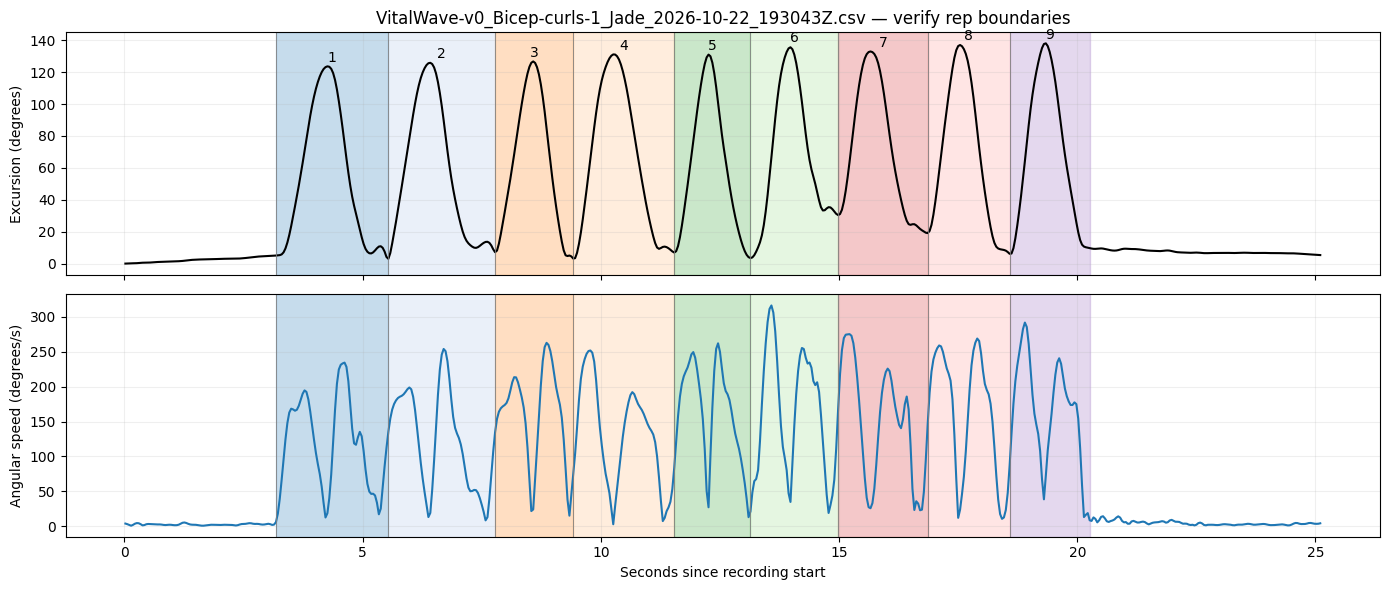

,rep,start_s,end_s,completion_error_deg,peak_excursion_deg,gyro_mean_deg_s,gyro_peak_deg_s,gyro_std_deg_s,accel_magnitude_std_g,gyro_high_low_power_ratio
0,1,3.18,5.54,8.2011,126.4201,117.8456,234.4002,65.7022,0.1613,0.0500
1,2,5.54,7.78,5.3106,122.4227,122.9878,253.9448,70.7074,0.1646,0.0104
2,3,7.78,9.42,4.8614,124.9767,158.1379,262.7095,68.1372,0.2150,0.0329
3,4,9.42,11.54,5.6327,130.6788,128.6523,251.7746,71.9160,0.1735,0.0215
4,5,11.54,13.14,6.1404,128.6702,160.6877,262.0433,71.8731,0.2440,0.1954
5,6,13.14,14.98,28.8250,132.6448,159.7039,316.2646,88.2082,0.2645,0.0808
6,7,14.98,16.86,11.9089,125.0931,148.7423,275.2275,82.0533,0.2264,0.0613
7,8,16.86,18.58,15.9330,128.9492,159.8670,268.8858,87.3072,0.2341,0.0317
8,9,18.58,20.26,5.1771,137.3120,162.4384,291.7630,77.5746,0.2311,0.0755


,n_reps,mean,sd,lower_3sd,upper_3sd
completion_error_deg,9,10.2212,7.9187,0.0000,33.9773
peak_excursion_deg,9,128.5742,4.5420,114.9482,142.2002
gyro_mean_deg_s,9,146.5625,18.1701,92.0523,201.0728
gyro_peak_deg_s,9,268.5570,23.9729,196.6382,340.4759
gyro_std_deg_s,9,75.9421,8.2581,51.1677,100.7166
accel_magnitude_std_g,9,0.2127,0.0373,0.1008,0.3247
gyro_high_low_power_ratio,9,0.0622,0.0554,0.0000,0.2284


Seven features; duration is excluded. Baseline limits are now fixed for cell 2.
Watch placement and signal quality can still affect these features.
These are estimated watch motions, not anatomical joint angles or tremor diagnoses.


In [5]:
from pathlib import Path
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, periodogram, resample_poly
from scipy.spatial.transform import Rotation
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)

ROOT = Path(
    "/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo"
)

BASELINE_FILE = ROOT / "Data/new_watch/VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193043Z.csv"

FILES = [
    ROOT / "Data/new_watch/VitalWave-v0_Bicep-curls-2nd-and-3rd-is-atypical_Jade_2026-10-22_204614Z.csv",
    ROOT / "Data/new_watch/VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-atypical_Jade_2026-10-22_200600Z.csv",
]

FEATURE_LABELS = {
    "completion_error_deg": "Completion error (degrees)",
    "peak_excursion_deg": "Peak orientation excursion (degrees)",
    "gyro_mean_deg_s": "Mean angular speed (degrees/s)",
    "gyro_peak_deg_s": "Peak angular speed (degrees/s)",
    "gyro_std_deg_s": "Angular-speed SD (degrees/s)",
    "accel_magnitude_std_g": "Acceleration-magnitude SD (g)",
    "gyro_high_low_power_ratio": "High/low frequency-power ratio",
}
FEATURES = list(FEATURE_LABELS)

def extract_recording_features(csv_path):
    """Same orientation-based approach, with final-rep stillness confirmation."""
    data = pd.read_csv(csv_path)

    if data["protocol_session_id"].nunique() != 1:
        raise ValueError("Expected one recording session.")

    t0 = data["watch_timestamp_ms"].min() / 1000
    streams = {}

    for sensor_type, scale in [(1, 0.000061), (2, 0.00875)]:
        d = data.loc[data["type"] == sensor_type].copy()

        valid = pd.to_numeric(d["validity"], errors="coerce").eq(1)
        print(f"  Sensor {sensor_type}: excluding {(~valid).sum()} invalid samples.")
        d = d.loc[valid].copy()

        if len(d) < 30:
            raise ValueError(f"Sensor {sensor_type}: too few valid samples.")

        ts = d["watch_timestamp_ms"].to_numpy(float) / 1000 - t0
        values = d[["x_raw", "y_raw", "z_raw"]].to_numpy(float) * scale

        if not np.isfinite(values).all() or not np.isfinite(ts).all():
            raise ValueError("Nonfinite data.")
        if np.any(np.diff(ts) <= 0):
            raise ValueError("Duplicate or out-of-order timestamps.")

        dt = np.median(np.diff(ts))
        gaps = np.diff(ts)

        # Allow isolated short gaps, but do not bridge long missing sections.
        if gaps.max() > 2.1 * dt + 0.001:
            raise ValueError("Large timestamp gap: inspect/split recording first.")

        missing_intervals = np.count_nonzero(gaps > 1.5 * dt)
        if missing_intervals:
            print(
                f"  Sensor {sensor_type}: interpolating "
                f"{missing_intervals} short timestamp gap(s)."
            )

        streams[sensor_type] = (ts, values, dt)

    measured_fs = 1 / streams[2][2]

    # Choose the nearest supported nominal rate, allowing timestamp jitter.
    supported_rates = np.array([25.0, 50.0])
    source_fs = int(
        supported_rates[np.argmin(np.abs(supported_rates - measured_fs))]
    )

    if abs(measured_fs - source_fs) / source_fs > 0.10:
        raise ValueError(
            f"Measured rate {measured_fs:.2f} Hz is too far from "
            f"the supported rates. Inspect timestamps."
        )

    if not np.isclose(streams[1][2], streams[2][2], rtol=0.10):
        raise ValueError("Sensor sampling rates differ substantially.")

    print(
        f"  Timestamp estimate: {measured_fs:.2f} Hz; "
        f"using a {source_fs} Hz uniform grid."
    )
    # Align at the source rate, then anti-alias before reducing 50 Hz to 25 Hz.
    source_t = np.arange(
        max(streams[1][0][0], streams[2][0][0]),
        min(streams[1][0][-1], streams[2][0][-1]) + 1e-8,
        1 / source_fs,
    )

    def align(sensor_type):
        ts, values, _ = streams[sensor_type]
        return np.column_stack([
            np.interp(source_t, ts, values[:, k]) for k in range(3)
        ])

    acc_raw, gyro_raw = align(1), align(2)
    down = source_fs // 25

    if down > 1:
        acc_raw = resample_poly(acc_raw, 1, down, axis=0, padtype="line")
        gyro_raw = resample_poly(gyro_raw, 1, down, axis=0, padtype="line")

    fs = 25.0
    t = source_t[0] + np.arange(len(gyro_raw)) / fs
    keep = t <= source_t[-1] + 1e-8
    t, acc_raw, gyro_raw = t[keep], acc_raw[keep], gyro_raw[keep]

    lead = t < t[0] + 2.0
    still = (
        lead.sum() >= 10
        and np.std(np.linalg.norm(acc_raw[lead], axis=1)) <= 0.03
        and np.max(np.linalg.norm(gyro_raw[lead], axis=1)) <= 5
    )

    if still:
        gyro_raw -= gyro_raw[lead].mean(axis=0)
    else:
        print("  Stillness check failed: no gyro bias correction applied.")

    sos = butter(4, 4.0, fs=fs, btype="lowpass", output="sos")
    acc = sosfiltfilt(sos, acc_raw, axis=0)
    gyro = sosfiltfilt(sos, gyro_raw, axis=0)

    # Orientation estimate.
    x, y, z = acc[0]
    r = Rotation.from_euler(
        "xyz",
        [np.arctan2(y, z), np.arctan2(-x, np.hypot(y, z)), 0],
    )
    r0 = r
    quats, angles = [r.as_quat()], [0.0]

    for i in range(1, len(t)):
        omega = np.deg2rad((gyro[i - 1] + gyro[i]) / 2)
        norm = np.linalg.norm(acc[i])
        if 0.85 <= norm <= 1.15:
            omega += 0.5 * np.cross(
                acc[i] / norm, r.inv().apply([0, 0, 1])
            )
        r = r * Rotation.from_rotvec(omega * (t[i] - t[i - 1]))
        quats.append(r.as_quat())
        angles.append(np.rad2deg((r0.inv() * r).magnitude()))

    quats = np.asarray(quats)
    history = deque(maxlen=max(1, round(0.1 * fs)))
    excursion = []
    for angle in angles:
        history.append(angle)
        excursion.append(np.mean(history))
    excursion = np.asarray(excursion)
    speed = np.linalg.norm(gyro, axis=1)

    # Same trough-to-trough detector.
    mode, low, high, start = "seek", None, None, None
    candidates = []

    for i in np.flatnonzero(~lead):
        value = excursion[i]
        if low is None:
            low = (i, value)
            continue

        if mode in ("seek", "rise"):
            if value < low[1]:
                low = (i, value)
            if mode == "seek" and value - low[1] >= 15:
                start, high, mode = low[0], (i, value), "rise"
            elif mode == "rise":
                if high is None or value > high[1]:
                    high = (i, value)
                if high[1] - value >= 8:
                    low, mode = (i, value), "fall"
        else:
            if value < low[1]:
                low = (i, value)
            if value - low[1] >= 8:
                candidates.append((start, low[0]))
                start, high, mode = low[0], (i, value), "rise"

    # Trim idle time before the first confirmed rep.
    rest_speed = speed[lead]
    onset = max(
        10.0,
        np.median(rest_speed)
        + 6 * np.median(np.abs(rest_speed - np.median(rest_speed))),
    )

    if candidates:
        a, b = candidates[0]
        hold = max(2, int(np.ceil(0.12 * fs)))
        for k in range(a, b - hold + 1):
            if np.all(speed[k:k + hold] > onset):
                candidates[0] = (max(a, k - 1), b)
                break

    # Final rep: return near start + 0.5 s sustained low speed.
    if start is not None and mode == "fall" and high is not None:
        peak_i, peak_value = high
        settled = (
            (np.abs(excursion - excursion[start]) <= 15)
            & (peak_value - excursion >= 8)
            & (speed <= 15)
        )
        settle_start = None

        if peak_value - excursion[start] >= 15:
            for i in range(peak_i + 1, len(t)):
                if settled[i]:
                    if settle_start is None:
                        settle_start = i
                    if t[i] - t[settle_start] >= 0.5:
                        candidates.append((start, settle_start))
                        start = None
                        break
                else:
                    settle_start = None

    rows, accepted = [], []
    for a, b in candidates:
        if not 0.6 <= t[b] - t[a] <= 8:
            continue
        if np.ptp(excursion[a:b + 1]) < 15:
            continue

        section = slice(a, b + 1)
        rep_speed = speed[section]

        error = np.rad2deg(
            (
                Rotation.from_quat(quats[a]).inv()
                * Rotation.from_quat(quats[b])
            ).magnitude()
        )

        # Before the 4 Hz smoothing, but after any anti-alias resampling.
        freq, power = periodogram(
            np.linalg.norm(gyro_raw[section], axis=1),
            fs=fs,
            window="hann",
            detrend="constant",
            scaling="spectrum",
        )
        low_power = power[(freq >= 0.1) & (freq <= 2)].sum()
        high_power = power[(freq >= 3) & (freq <= 8)].sum()

        peak_excursion = np.rad2deg(
            (Rotation.from_quat(quats[a]).inv() * Rotation.from_quat(quats[section])).magnitude()
        ).max()
        accepted.append((a, b))
        rows.append({
            "rep": len(rows) + 1,
            "start_s": t[a],
            "end_s": t[b],
            "completion_error_deg": error,
            "peak_excursion_deg": peak_excursion,
            "gyro_mean_deg_s": rep_speed.mean(),
            "gyro_peak_deg_s": rep_speed.max(),
            "gyro_std_deg_s": rep_speed.std(),
            "accel_magnitude_std_g": np.linalg.norm(
                acc[section], axis=1
            ).std(),
            "gyro_high_low_power_ratio": (
                high_power / low_power if low_power > 1e-12 else np.nan
            ),
        })

    print(
        f"  Source: ~{measured_fs:.1f} Hz; analysis: 25 Hz; "
        f"{len(rows)} candidate reps."
    )
    if start is not None:
        print("  Unconfirmed final movement excluded; inspect segmentation.")

    return {
        "table": pd.DataFrame(rows, columns=["rep", "start_s", "end_s"] + FEATURES),
        "t": t, "excursion": excursion,
        "speed": speed, "accepted": accepted, "tail_start": start,
        "name": Path(csv_path).name,
    }



def plot_segmentation(recording):
    t = recording["t"]
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    axes[0].plot(t, recording["excursion"], color="black")
    axes[1].plot(t, recording["speed"], color="tab:blue")
    for rep, (a, b) in enumerate(recording["accepted"], 1):
        for ax in axes:
            ax.axvspan(t[a], t[b], color=plt.cm.tab20((rep-1) % 20), alpha=.25)
            ax.axvline(t[a], color="gray", lw=.6)
        axes[0].text((t[a]+t[b])/2,
                     recording["excursion"][a:b+1].max()+3, str(rep), ha="center")
    if recording["tail_start"] is not None:
        for ax in axes:
            ax.axvspan(t[recording["tail_start"]], t[-1], color="gray", alpha=.15, hatch="//")
    axes[0].set_ylabel("Excursion (degrees)")
    axes[1].set_ylabel("Angular speed (degrees/s)")
    axes[1].set_xlabel("Seconds since recording start")
    axes[0].set_title(recording["name"] + " — verify rep boundaries")
    for ax in axes: ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()

BASELINE_FILE = ROOT / "Data/new_watch/VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193043Z.csv"
# None uses all detected baseline reps provisionally. After reviewing the plot,
# replace with approved rep IDs, e.g. [1, 2, 3, 4, 5], and rerun both cells.
APPROVED_BASELINE_REPS = None
baseline_recording = extract_recording_features(BASELINE_FILE)
if baseline_recording["table"].empty:
    raise ValueError("No baseline reps detected.")
selected = (baseline_recording["table"]["rep"].tolist()
            if APPROVED_BASELINE_REPS is None else APPROVED_BASELINE_REPS)
if len(set(selected)) < 3 or len(set(selected)) != len(selected):
    raise ValueError("Select at least three unique approved baseline rep IDs.")
if not set(selected).issubset(set(baseline_recording["table"]["rep"])):
    raise ValueError("Unknown baseline rep ID.")
baseline_table = baseline_recording["table"].copy()
baseline_features = baseline_table.set_index("rep").loc[selected, FEATURES].copy()
if not np.isfinite(baseline_features.to_numpy()).all():
    raise ValueError("Undefined baseline features; inspect recordings before proceeding.")
baseline_stats = pd.DataFrame({
    "n_reps": len(baseline_features), "mean": baseline_features.mean(),
    "sd": baseline_features.std(ddof=1),
})
baseline_stats["lower_3sd"] = (baseline_stats["mean"] - 3*baseline_stats["sd"]).clip(lower=0)
baseline_stats["upper_3sd"] = baseline_stats["mean"] + 3*baseline_stats["sd"]
# Physical upper bounds.
for key, maximum in [("completion_error_deg", 180), ("peak_excursion_deg", 180)]:
    baseline_stats.loc[key, "upper_3sd"] = min(baseline_stats.loc[key, "upper_3sd"], maximum)
plot_segmentation(baseline_recording)
display(baseline_table.round(4))
display(baseline_stats.round(4))
print("Seven features; duration is excluded. Baseline limits are now fixed for cell 2.")
print("Watch placement and signal quality can still affect these features.")
print("These are estimated watch motions, not anatomical joint angles or tremor diagnoses.")
if (baseline_stats["sd"] < 1e-10).any():
    print("Warning: near-zero baseline SD; corresponding thresholds need review.")


## Compare test recordings against the fixed baseline


VitalWave-v0_Bicep-curls-2nd-and-3rd-is-atypical_Jade_2026-10-22_204614Z.csv
  Sensor 1: excluding 0 invalid samples.
  Sensor 2: excluding 0 invalid samples.
  Timestamp estimate: 25.00 Hz; using a 25 Hz uniform grid.
  Stillness check failed: no gyro bias correction applied.
  Source: ~25.0 Hz; analysis: 25 Hz; 6 candidate reps.


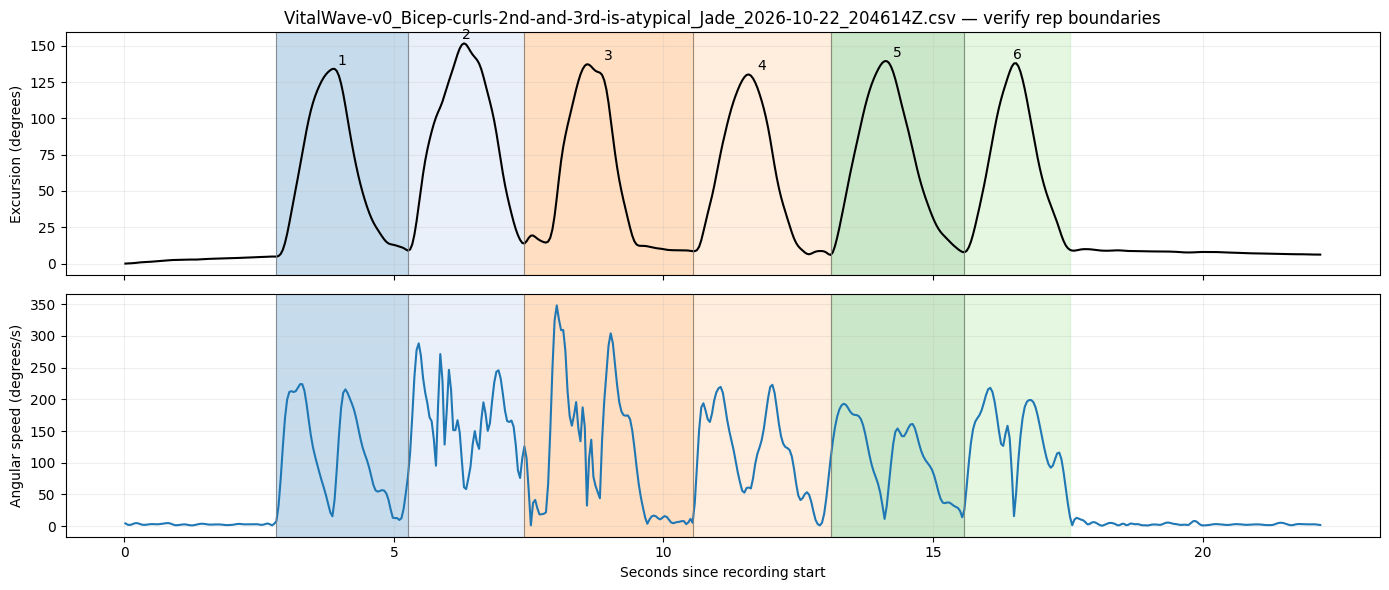

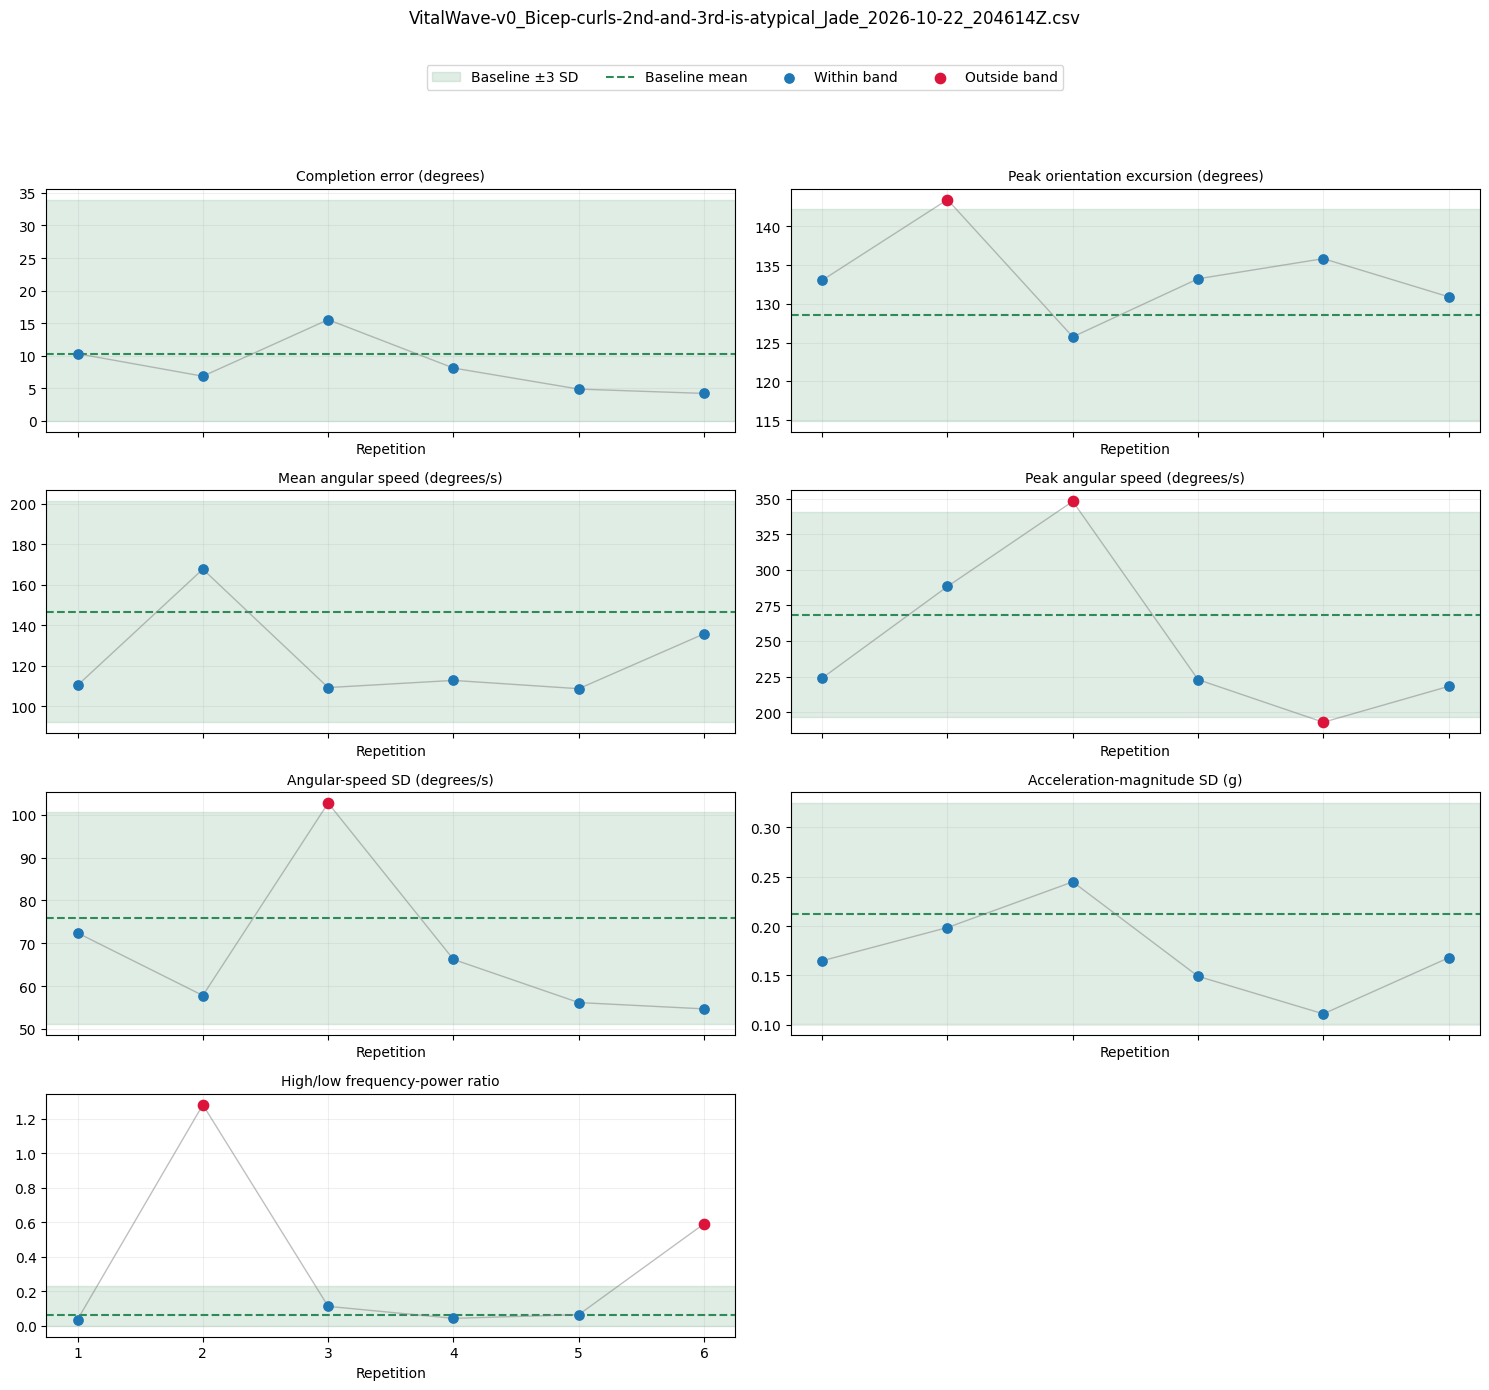

,rep,start_s,end_s,features_outside_band,missing_features
0,1,2.821,5.261,None,None
1,2,5.261,7.421,"peak_excursion_deg, gyro_high_low_power_ratio",None
2,3,7.421,10.541,"gyro_peak_deg_s, gyro_std_deg_s",None
3,4,10.541,13.101,None,None
4,5,13.101,15.581,gyro_peak_deg_s,None
5,6,15.581,17.541,gyro_high_low_power_ratio,None


,rep,start_s,end_s,completion_error_deg,peak_excursion_deg,gyro_mean_deg_s,gyro_peak_deg_s,gyro_std_deg_s,accel_magnitude_std_g,gyro_high_low_power_ratio
0,1,2.821,5.261,10.2777,133.0527,110.2901,223.9746,72.4142,0.1648,0.0355
1,2,5.261,7.421,6.8177,143.4555,167.5992,288.2468,57.8115,0.1985,1.2820
2,3,7.421,10.541,15.5137,125.7446,109.1687,347.9925,102.7364,0.2448,0.1120
3,4,10.541,13.101,8.0755,133.2423,112.7004,222.8715,66.2384,0.1491,0.0427
4,5,13.101,15.581,4.8347,135.8385,108.6069,192.9595,56.1639,0.1110,0.0640
5,6,15.581,17.541,4.1681,130.9169,135.6764,218.1394,54.6908,0.1679,0.5913



VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-atypical_Jade_2026-10-22_200600Z.csv
  Sensor 1: excluding 29 invalid samples.
  Sensor 1: interpolating 59 short timestamp gap(s).
  Sensor 2: excluding 29 invalid samples.
  Sensor 2: interpolating 59 short timestamp gap(s).
  Timestamp estimate: 50.00 Hz; using a 50 Hz uniform grid.
  Stillness check failed: no gyro bias correction applied.
  Source: ~50.0 Hz; analysis: 25 Hz; 7 candidate reps.


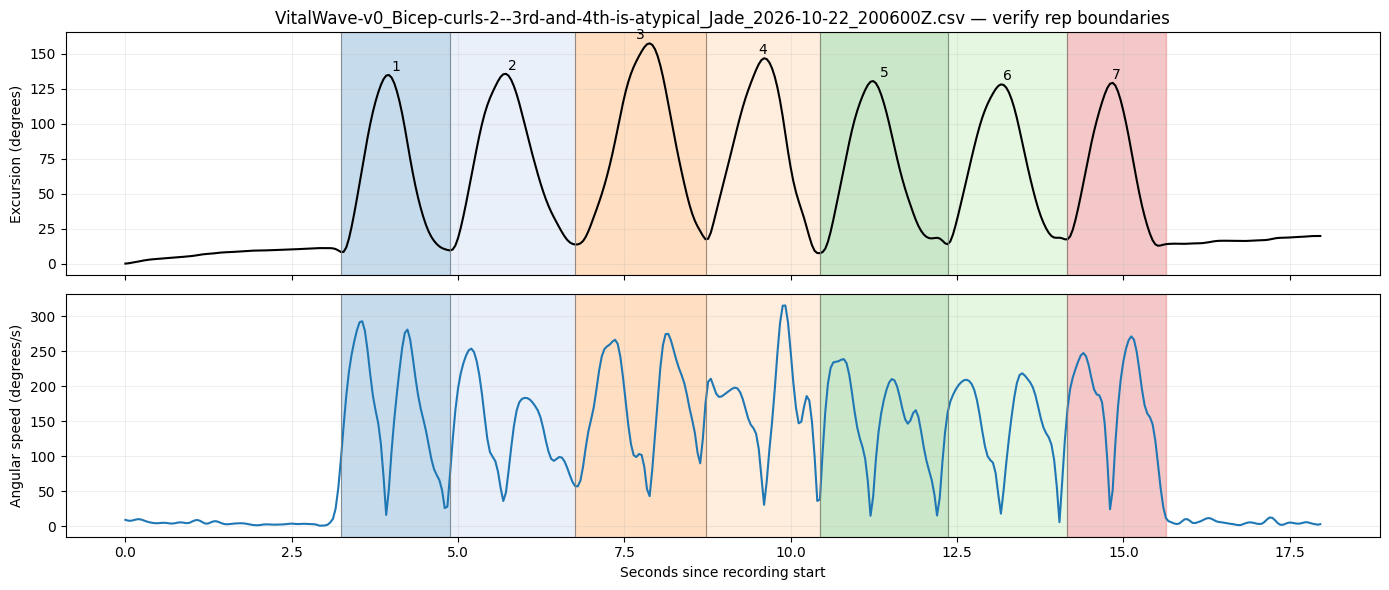

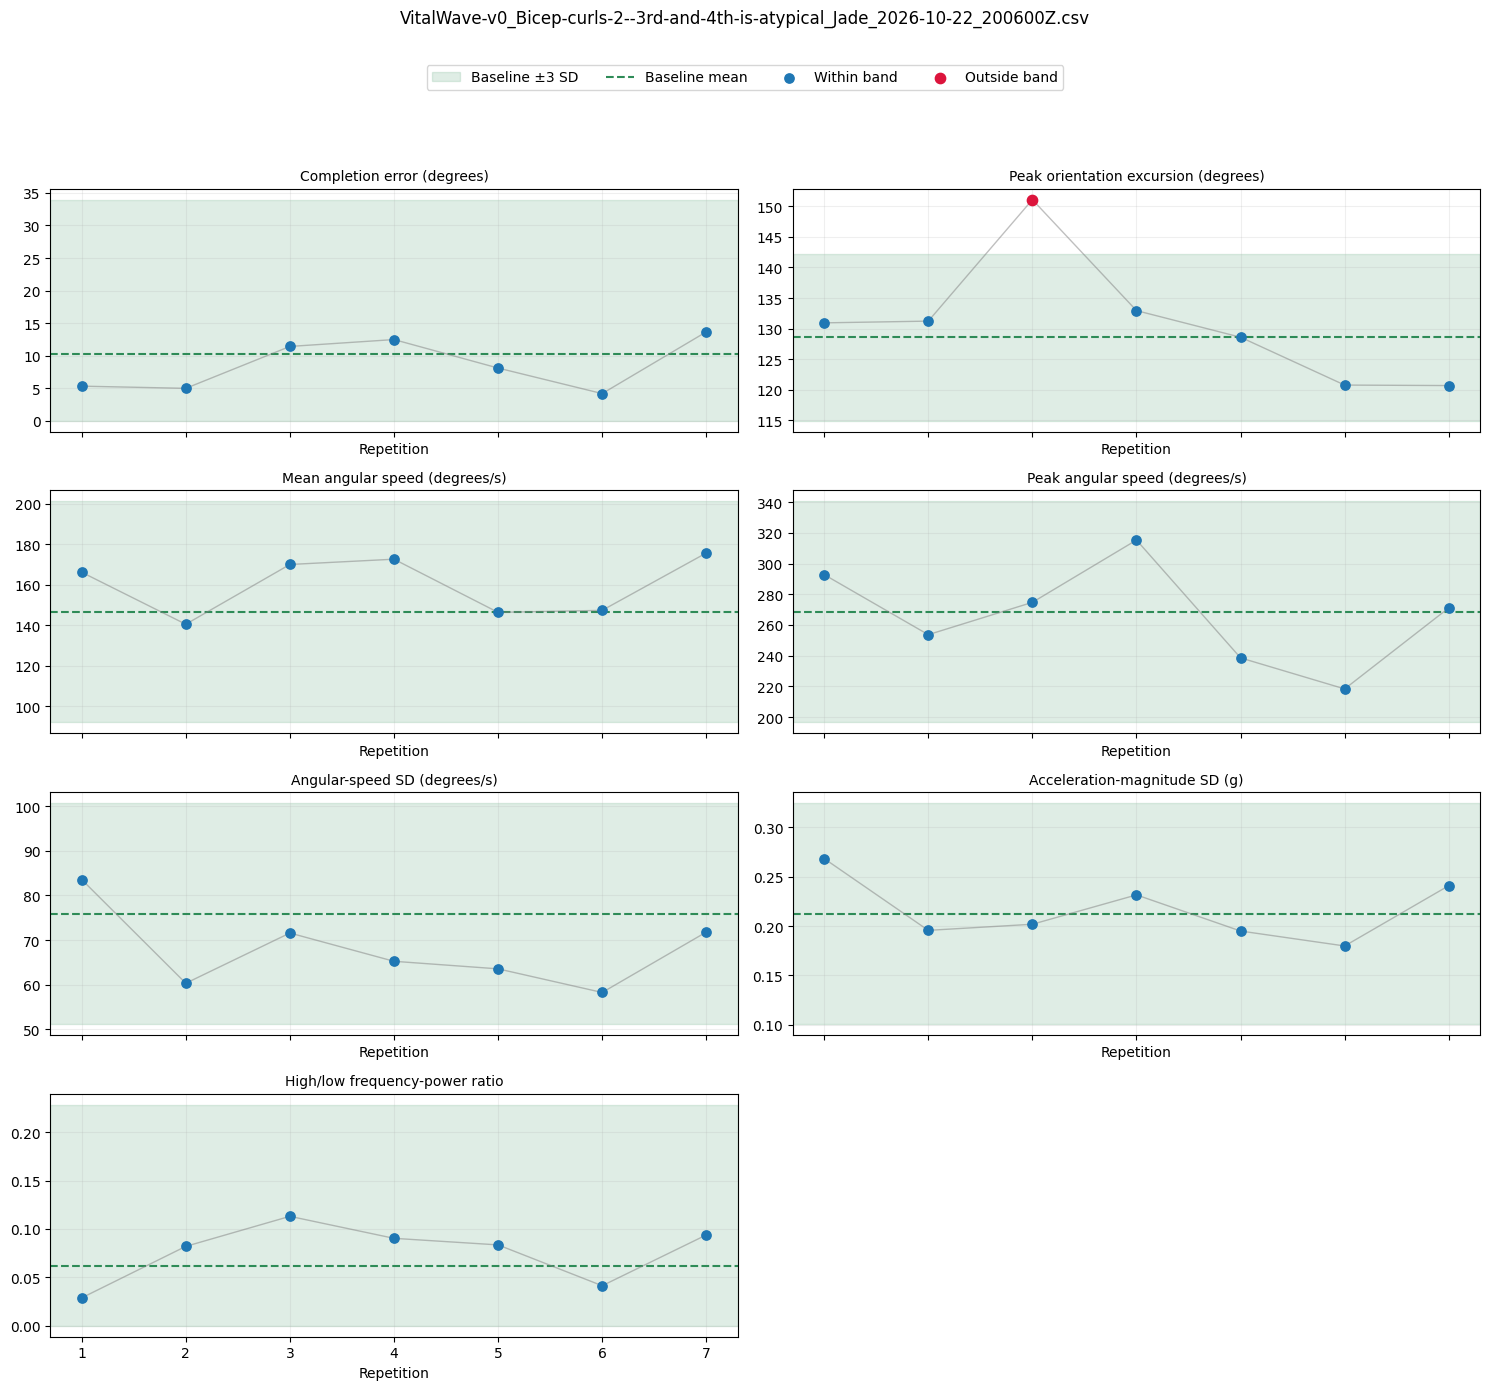

,rep,start_s,end_s,features_outside_band,missing_features
0,1,3.24,4.88,None,None
1,2,4.88,6.76,None,None
2,3,6.76,8.72,peak_excursion_deg,None
3,4,8.72,10.44,None,None
4,5,10.44,12.36,None,None
5,6,12.36,14.16,None,None
6,7,14.16,15.64,None,None


,rep,start_s,end_s,completion_error_deg,peak_excursion_deg,gyro_mean_deg_s,gyro_peak_deg_s,gyro_std_deg_s,accel_magnitude_std_g,gyro_high_low_power_ratio
0,1,3.24,4.88,5.2878,130.9340,166.0810,292.7562,83.5634,0.2684,0.0288
1,2,4.88,6.76,4.9511,131.2173,140.4247,253.6643,60.2997,0.1957,0.0820
2,3,6.76,8.72,11.3958,151.1008,169.9196,274.7092,71.5684,0.2019,0.1131
3,4,8.72,10.44,12.4540,132.9379,172.5277,315.2780,65.2260,0.2316,0.0903
4,5,10.44,12.36,8.0717,128.5793,146.2808,238.5411,63.5304,0.1950,0.0835
5,6,12.36,14.16,4.1432,120.7513,147.2793,218.3328,58.2312,0.1798,0.0413
6,7,14.16,15.64,13.6349,120.6699,175.5800,271.1112,71.7764,0.2410,0.0938


Red means outside this provisional baseline, not necessarily incorrect exercise.
Seven comparisons increase false-alarm opportunities; evaluate on additional labeled recordings.
Frequency ratio remains exploratory: interpolation and acquisition-rate differences affect it.


In [6]:
# Run cell 1 first. This cell never refits the baseline on test recordings.
import hashlib
reference = baseline_stats.copy(deep=True)
comparison_results = {}
seen_hashes = {}

for file_path in FILES:
    print("\n" + file_path.name)
    digest = hashlib.sha256(file_path.read_bytes()).hexdigest()
    if digest in seen_hashes:
        print("Identical file contents to:", seen_hashes[digest])
    seen_hashes[digest] = file_path.name
    recording = extract_recording_features(file_path)
    if recording["table"].empty:
        print("No repetitions detected; inspect this recording.")
        continue
    reps = recording["table"].copy()
    plot_segmentation(recording)
    values = reps.set_index("rep")[FEATURES]
    lower, upper = reference["lower_3sd"], reference["upper_3sd"]
    flags = values.lt(lower, axis="columns") | values.gt(upper, axis="columns")
    z_scores = values.sub(reference["mean"], axis="columns").div(
        reference["sd"].where(reference["sd"] > 1e-10), axis="columns")
    summary = reps[["rep", "start_s", "end_s"]].copy()
    summary["features_outside_band"] = [
        ", ".join(flags.columns[row.to_numpy()]) or "None" for _, row in flags.iterrows()]
    summary["missing_features"] = [
        ", ".join(values.columns[row.to_numpy()]) or "None" for _, row in values.isna().iterrows()]
    comparison_results[file_path.name] = {
        "features": reps, "flags": flags, "z_scores": z_scores,
        "summary": summary, "recording": recording,
    }
    fig, axes = plt.subplots(4, 2, figsize=(15, 14), sharex=True)
    for ax, feature in zip(axes.flat, FEATURES):
        y, outside = values[feature], flags[feature]
        ax.axhspan(lower[feature], upper[feature], color="seagreen", alpha=.15, label="Baseline ±3 SD")
        ax.axhline(reference.loc[feature, "mean"], color="seagreen", ls="--", label="Baseline mean")
        ax.plot(values.index, y, color="gray", lw=1, alpha=.5)
        ax.scatter(values.index[~outside], y[~outside], color="tab:blue", s=45, label="Within band", zorder=3)
        ax.scatter(values.index[outside], y[outside], color="crimson", s=55, label="Outside band", zorder=4)
        ax.set_title(FEATURE_LABELS[feature], fontsize=10)
        ax.set_xticks(values.index)
        ax.grid(alpha=.2)
    for ax in list(axes.flat)[len(FEATURES):]: ax.set_visible(False)
    for ax in list(axes.flat)[:len(FEATURES)]: ax.set_xlabel("Repetition")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5,.955), ncol=4)
    fig.suptitle(file_path.name, fontsize=12, y=.99)
    fig.tight_layout(rect=[0,0,1,.91])
    plt.show()
    display(summary.round(3))
    display(reps.round(4))
print("Red means outside this provisional baseline, not necessarily incorrect exercise.")
print("Seven comparisons increase false-alarm opportunities; evaluate on additional labeled recordings.")
print("Frequency ratio remains exploratory: interpolation and acquisition-rate differences affect it.")


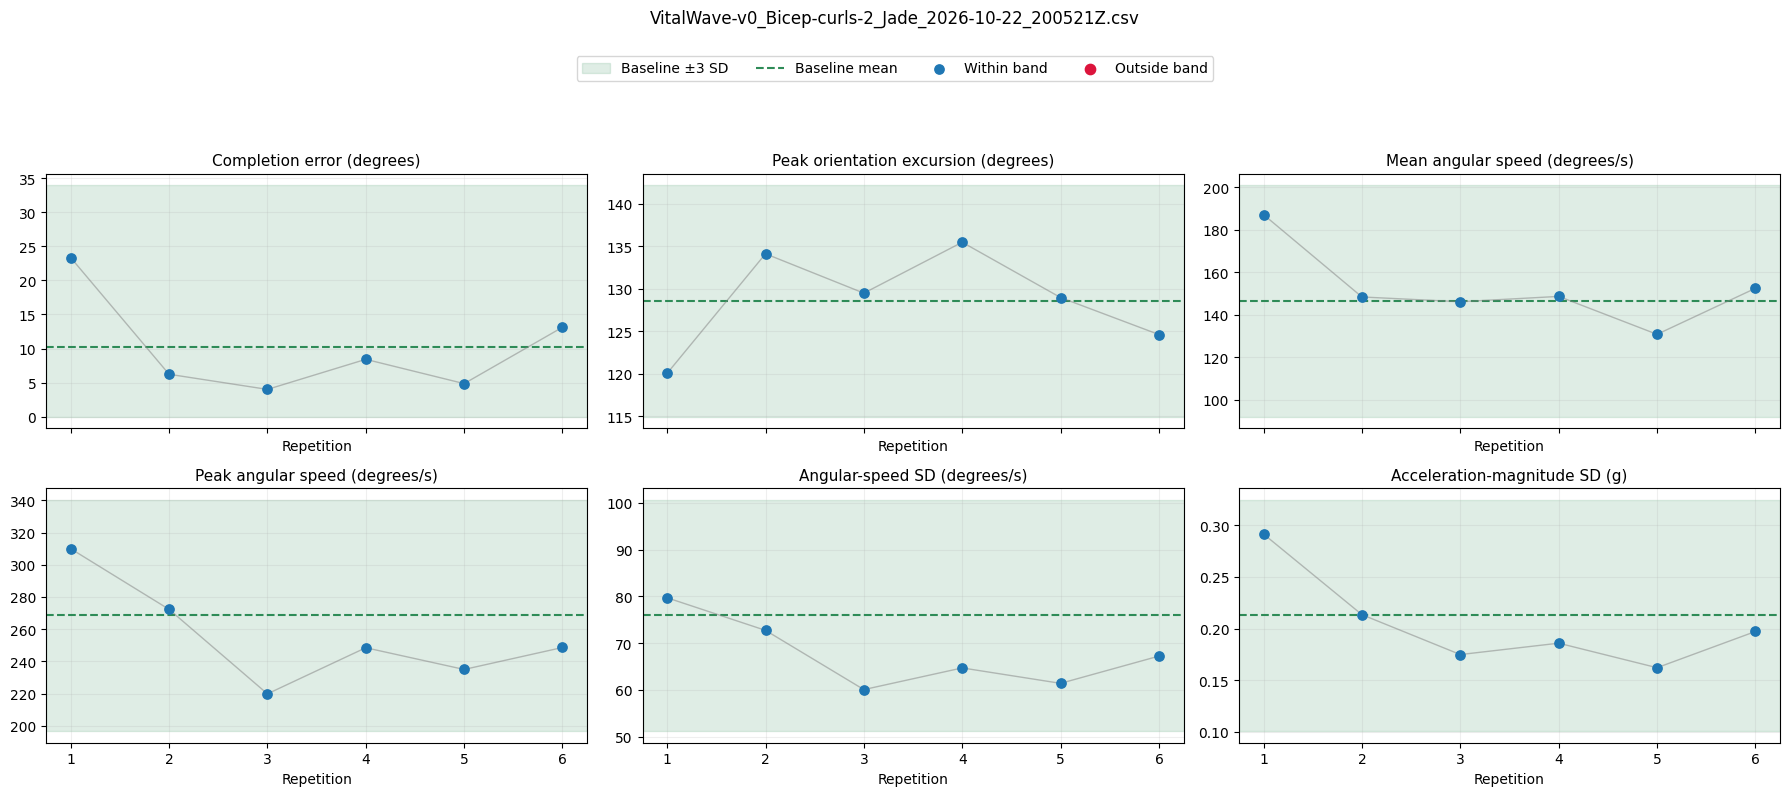

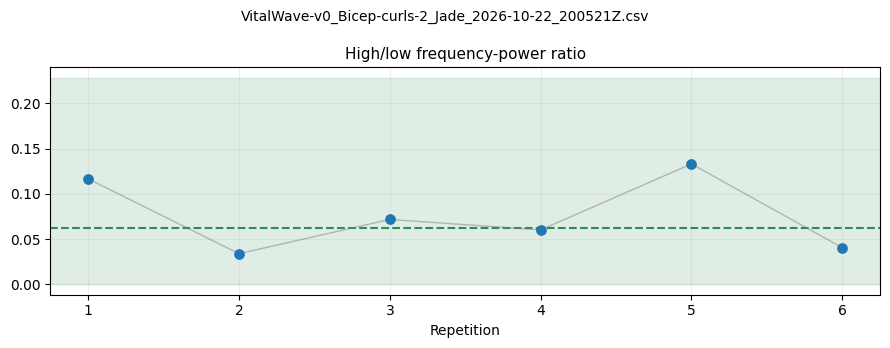

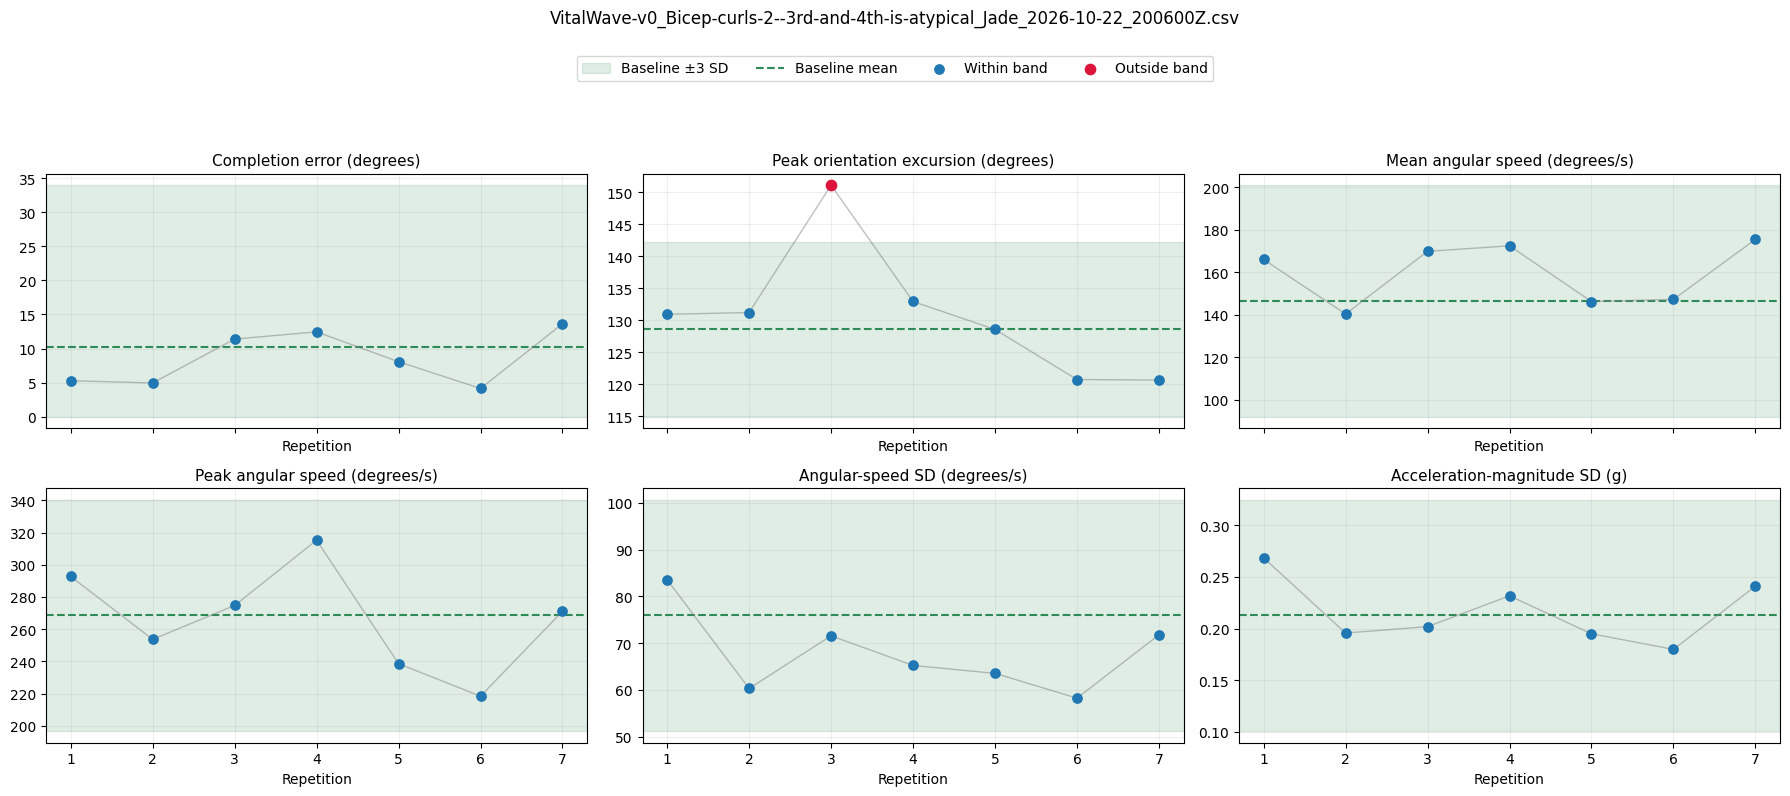

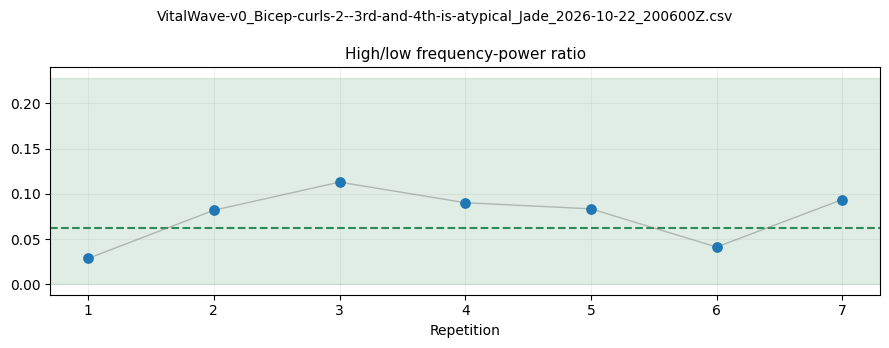

In [4]:
import matplotlib.pyplot as plt

def draw_feature(ax, values, feature):
    y = values[feature]
    limits = baseline_stats.loc[feature]
    outside = (y < limits["lower_3sd"]) | (y > limits["upper_3sd"])

    ax.axhspan(
        limits["lower_3sd"], limits["upper_3sd"],
        color="seagreen", alpha=0.15, label="Baseline ±3 SD"
    )
    ax.axhline(
        limits["mean"], color="seagreen", linestyle="--",
        label="Baseline mean"
    )
    ax.plot(values.index, y, color="gray", linewidth=1, alpha=0.5)
    ax.scatter(
        values.index[~outside], y[~outside],
        color="tab:blue", s=45, zorder=3, label="Within band"
    )
    ax.scatter(
        values.index[outside], y[outside],
        color="crimson", s=55, zorder=4, label="Outside band"
    )

    ax.set_title(FEATURE_LABELS[feature], fontsize=11)
    ax.set_xlabel("Repetition")
    ax.set_xticks(values.index)
    ax.grid(alpha=0.2)


main_features = [
    "completion_error_deg",
    "peak_excursion_deg",
    "gyro_mean_deg_s",
    "gyro_peak_deg_s",
    "gyro_std_deg_s",
    "accel_magnitude_std_g",
]

for filename, result in comparison_results.items():
    values = result["features"].set_index("rep")

    # Main figure: two rows, three columns.
    fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)

    for ax, feature in zip(axes.flat, main_features):
        draw_feature(ax, values, feature)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center",
        bbox_to_anchor=(0.5, 0.94), ncol=4
    )
    fig.suptitle(filename, fontsize=12, y=0.99)
    fig.tight_layout(rect=[0, 0, 1, 0.87])
    plt.show()

    # Seventh feature, retained separately.
    fig, ax = plt.subplots(figsize=(9, 3.5))
    draw_feature(ax, values, "gyro_high_low_power_ratio")
    fig.suptitle(filename, fontsize=10)
    fig.tight_layout()
    plt.show()